
# Foundations of Machine Learning: An Introduction to Neural Networks & MLPs
This notebook is a tutorial on **Neural Networks**. It starts with the basic building block, the "neuron," and builds its way up to a more powerful model capable of solving complex problems: the **Multi-Layered Perceptron (MLP)**.

At the end is a workshop on classifying handwritten digits from the MNIST dataset.

You will be asked to compare the Keras, PyTorch and TensorFlow implementations in terms of accuracy and speed.

<br/>
<br/>

### 💡 Additional Reading Material

These other tutorials come from the Course Notebooks Repository:

> In-depth: 
[**Multiclass Classification - A Simple Keras Model (MNIST)**](https://github.com/CSCN8010/CSCN8010/blob/main/dl_class_notebooks/03A_minimal_mnist_keras.ipynb)

> In-depth: 
[**Train and Aave a Simple Keras Model (MNIST)**](https://github.com/CSCN8010/CSCN8010/blob/main/dl_class_notebooks/03D_keras_checkpoints_save_model.ipynb)

> In-depth: 
[**Loading a pre-trained Keras model and classifying digits (MNIST)**](https://github.com/CSCN8010/CSCN8010/blob/main/dl_class_notebooks/03B_load_minimal_mnist_model.ipynb)  

<br/>
<br/>

***



### 1. The Inspiration: From Biological to Artificial Neurons

At its core, the field of neural networks is inspired by the human brain. We'll start by understanding the basic concept of a neuron.

#### **Key Concepts: The Neuron**

- An artificial intelligence (AI) system is designed to perceive its environment and act accordingly. 
- Neural networks are the "brain" of these systems.
- The simplest neural network is a **perceptron**, which consists of a single artificial neuron.
- The concept of an artificial neuron is modeled after a biological one.

* A **biological neuron** receives electrical signals through its *dendrites*. If the combined strength of these signals surpasses a certain threshold, the neuron "fires," sending an output signal through its *synapses* to other neurons.
* An **artificial neuron** works similarly. It receives multiple *inputs*, performs a calculation, and if the result exceeds a threshold, it produces an *output*.



### 2. The Perceptron: A Single Neuron in Action

Let's break down the mechanics of that single artificial neuron, the perceptron.

#### **Presentation: Anatomy of a Perceptron**

A perceptron operates on a simple principle: it takes a set of inputs, weighs them based on their importance, sums them up, and then uses an **activation function** to decide whether to "fire" and produce an output.

Here are the key components:

1.  **Inputs ($x$)**: These are the features of your data. For example, if you're predicting a house price, inputs could be the size, number of rooms, and age of the house. Each input is a feature that contributes to the final decision.

2.  **Weights ($w$)**: Not all inputs are equally important. Each input feature ($x_i$) is assigned a weight ($w_i$) that reflects its importance in the decision-making process. A higher weight amplifies an input's effect, while a lower weight diminishes it. The network learns these weights during training.

3.  **Weighted Sum ($z$)**: The neuron calculates the sum of all inputs multiplied by their corresponding weights. We also add a **bias ($b$)**, which is like the y-intercept in a linear equation. It allows us to shift the activation function, giving the model more flexibility. The formula is:
    $$z = (x_1w_1 + x_2w_2 + ... + x_nw_n) + b = \sum_{i=1}^{n} x_i w_i + b$$

4.  **Activation Function ($f(z)$)**: This is the decision-making unit of the neuron. It takes the weighted sum ($z$) as input and transforms it into the final output. For a simple step function, the output is either 0 or 1. This introduces non-linearity, which is crucial for learning complex patterns.



#### **Building a Perceptron with Python**

Let's build a simple perceptron from scratch using NumPy to see these concepts in code. We'll use a simple "step" activation function.


In [1]:
import numpy as np

# A simple perceptron class
class Perceptron:
    """A single neuron model."""

    def __init__(self, num_inputs):
        """
        Initializes the perceptron.
        Args:
            num_inputs (int): The number of input features.
        """
        # Initialize weights with small random numbers. Bias is the last weight.
        self.weights = np.random.rand(num_inputs + 1)
        print(f"Initialized weights: {self.weights}")

    def step_function(self, z):
        """The activation function."""
        return 1 if z >= 0 else 0

    def predict(self, inputs):
        """
        Calculates the weighted sum and passes it to the activation function.
        Args:
            inputs (list or np.array): The input features.
        Returns:
            int: The binary output (0 or 1).
        """
        # Add the bias input (always 1)
        inputs_with_bias = np.append(inputs, 1)

        # Calculate the weighted sum: z = sum(x_i * w_i)
        z = np.dot(inputs_with_bias, self.weights)
        print(f"Inputs (with bias): {inputs_with_bias}")
        print(f"Weighted Sum (z): {z:.4f}")

        # Apply the activation function
        output = self.step_function(z)
        print(f"Output: {output}")
        return output

# --- Let's test our Perceptron! ---
# Create a perceptron that takes 2 inputs
p = Perceptron(num_inputs=2)

# Define some sample inputs
sample_inputs = np.array([0.8, 0.5])

# Make a prediction
prediction = p.predict(sample_inputs)
print(f"\nFinal prediction for inputs {sample_inputs} is: {prediction}")


Initialized weights: [0.13728965 0.40173168 0.49966979]
Inputs (with bias): [0.8 0.5 1. ]
Weighted Sum (z): 0.8104
Output: 1

Final prediction for inputs [0.8 0.5] is: 1



### 3. Activation Functions: Adding Non-Linearity

[cite_start]A single perceptron with a step function can only separate data with a single straight line[cite: 178]. To learn truly complex patterns, like those in images or speech, we need more sophisticated activation functions that introduce **non-linearity**.

#### **Presentation: Common Activation Functions**

While there are many activation functions, three are particularly common and important to know. [cite_start]The PDF specifically mentions **ReLU** and **softmax** as popular choices[cite: 280].

1.  **Sigmoid (or Logistic)**
    * **Formula**: $\sigma(z) = \frac{1}{1 + e^{-z}}$
    * **Output Range**: (0, 1)
    * **Use Case**: Excellent for binary classification problems where the output needs to be a probability.
    * **Downside**: Suffers from the "vanishing gradient" problem, which can slow down learning in deep networks.

2.  **Tanh (Hyperbolic Tangent)**
    * **Formula**: $\tanh(z) = \frac{e^z - e^{-z}}{e^z + e^{-z}}$
    * **Output Range**: (-1, 1)
    * **Use Case**: Similar to sigmoid but is "zero-centered," which can sometimes help models learn faster.
    * **Downside**: Also suffers from the vanishing gradient problem.

3.  **ReLU (Rectified Linear Unit)**
    * **Formula**: $R(z) = \max(0, z)$
    * **Output Range**: [0, $\infty$)
    * **Use Case**: The most popular activation function for hidden layers in deep learning. It's computationally very efficient and helps mitigate the vanishing gradient problem.
    * **Downside**: Can "die" if a neuron's output consistently becomes zero, preventing weight updates.



#### **Visualizing Activation Functions**

Let's plot these functions to understand their behavior.


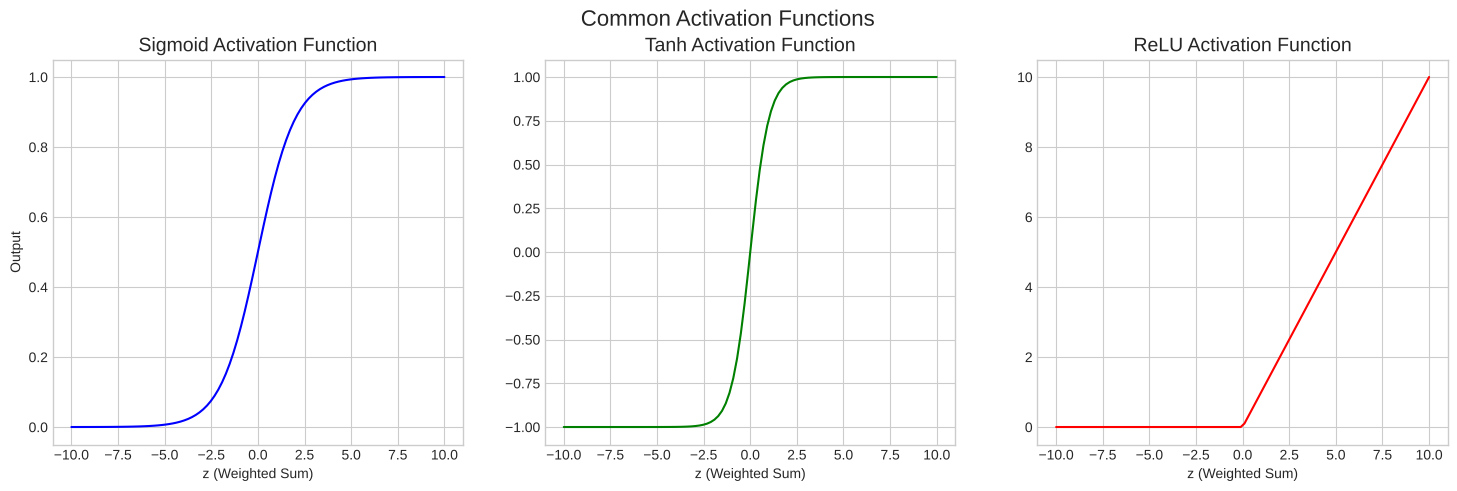

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Define the input range
z = np.linspace(-10, 10, 100)

# Define the activation functions
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def tanh(x):
    return np.tanh(x)

def relu(x):
    return np.maximum(0, x)

# Plotting
plt.style.use('seaborn-v0_8-whitegrid')
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

axs[0].plot(z, sigmoid(z), color='blue')
axs[0].set_title('Sigmoid Activation Function', fontsize=14)
axs[0].set_xlabel('z (Weighted Sum)')
axs[0].set_ylabel('Output')

axs[1].plot(z, tanh(z), color='green')
axs[1].set_title('Tanh Activation Function', fontsize=14)
axs[1].set_xlabel('z (Weighted Sum)')

axs[2].plot(z, relu(z), color='red')
axs[2].set_title('ReLU Activation Function', fontsize=14)
axs[2].set_xlabel('z (Weighted Sum)')

plt.suptitle('Common Activation Functions', fontsize=16)
plt.show()



### 4. From One to Many: The Multi-Layer Perceptron (MLP)

A single neuron is limited. To solve complex, **non-linear problems**, we need to combine many neurons into a network.

#### **MLP Architecture**

A very common architecture is to stack neurons in layers. This creates a **Multi-Layer Perceptron (MLP)**. An MLP has three types of layers:

1.  **Input Layer**: This layer receives the initial feature vector. It doesn't perform calculations; it simply passes the data to the first hidden layer.
2.  **Hidden Layers**: These are the layers between the input and output. This is where most of the learning happens. Each neuron in a hidden layer receives outputs from the previous layer, performs the `weighted sum -> activation` calculation, and passes its output to the next layer. Networks with two or more hidden layers are often called **deep neural networks**.
3.  **Output Layer**: This is the final layer that produces the model's prediction. The number of neurons and the activation function in this layer depend on the problem you're solving (e.g., one neuron with a sigmoid for binary classification, or multiple neurons with a softmax function for multi-class classification).

In an MLP, layers are typically **fully connected**, meaning every neuron in one layer is connected to every neuron in the next layer.



### 5. The Learning Process: Feedforward & Backpropagation

How does an MLP actually *learn*? It's a two-part process that is repeated many times: **Feedforward** to make a prediction, and **Backpropagation** to correct errors.

#### **The Learning Loop**

**Step 1: Feedforward (Making a Prediction)**

This is the process of information flowing forward through the network.

1.  The input data is fed into the **input layer**.
2.  The data flows to the first **hidden layer**. Each neuron in this layer calculates its weighted sum and applies its activation function.
3.  The outputs of the first hidden layer become the inputs for the second hidden layer, and so on.
4.  This continues until the data reaches the **output layer**, which produces the final prediction ($y'$).

The entire process is a chain of `weighted sum -> activation` calculations, layer by layer, from input to output.

**Step 2: Backpropagation (Learning from Mistakes)**

Once the network makes a prediction ($y'$), we need to see how good it was.

1.  **Compute Error (Loss)**: We compare the network's prediction ($y'$) with the correct, true label ($y$). The difference is the **error**. We use an **error function** (or loss function) like Mean Squared Error or Cross-Entropy to calculate a single score representing how wrong the model was.
    * **Error Calculation**: `error = y - y'` 

2.  **Propagate Error Backwards**: This is the magic of backpropagation. The error is sent backward through the network, from the output layer to the input layer.

3.  **Update Weights**: As the error propagates back, it's used to calculate how much each weight and bias in the network contributed to the total error. The network then adjusts its weights to reduce the error. For instance, if a large weight led to a large error, the network will decrease that weight. This process uses calculus (specifically, an algorithm called **gradient descent**) to find the optimal weight values that minimize the error. For a more in-depth analysis of this method, read the tutorial at [3Blue1Brown - What is Backpropagation Really Doing?](https://www.3blue1brown.com/lessons/backpropagation)

4.  **Repeat**: This entire `feedforward -> backpropagation` cycle is repeated many times (for many **epochs**) with the entire training dataset. With each cycle, the network's weights get a little bit better, and its predictions become more and more accurate.


## 🔄 Understanding How the Model Compares Predictions to True Labels (Backpropagation Step 2)

During training, your model learns by comparing its **predicted output** to the **correct, true label** that comes from the dataset. This comparison happens **during every epoch**, and it is essential for calculating the **loss** (error), which drives backpropagation.

### ✅ What Happens During Training (Simplified View)

1. **Training Dataset**  
   You start with a dataset consisting of input–output pairs:  
   $$
   (X, y) = \\{(x^{(1)}, y^{(1)}), (x^{(2)}, y^{(2)}), ..., (x^{(n)}, y^{(n)})\\}
   $$
   - $x^{(i)}$ is the input vector (features)
   - $y^{(i)}$ is the correct, true label (target output)

2. **Model Initialization**  
   The model starts with **random weights**.

3. **Epoch Loop**  
   For each epoch:
   - For each mini-batch or training sample:
     1. Feed **input `x`** into the model → get prediction `y_pred`
     2. Compare `y_pred` with the **true label `y_true`**
     3. Compute **loss** using a loss function (e.g., MSE or Cross-Entropy)
     4. Perform **backpropagation** to compute gradients
     5. **Update weights** with an optimizer

### 🧠 Pseudocode: Training Up to Loss Calculation

```python
# Assume: training_data = [(x1, y1), (x2, y2), ..., (xn, yn)]
# x = input vector, y = true label

initialize_model_weights()

for epoch in range(num_epochs):
    for x, y_true in training_data:
        
        # ---- FEEDFORWARD ----
        y_pred = model.forward(x)  # Predict output based on current weights
        
        # ---- COMPARE PREDICTION TO TRUE LABEL ----
        # Step 1: Compute loss (error between prediction and true label)
        loss = loss_function(y_pred, y_true)  # e.g., MSE, Cross-Entropy

        # ---- BACKPROPAGATION ----
        gradients = compute_gradients(loss, model.weights)
        
        # ---- UPDATE WEIGHTS ----
        optimizer.step(model.weights, gradients)
````

### 💬 Where Does `y_true` Come From?

It comes from the **training dataset**, which:

* Is usually prepared as `(X_train, y_train)` arrays
* Or loaded using a **DataLoader** that returns `(x, y)` pairs

During training, for every training example or batch:

* The model uses the **input `x`** to make a prediction
* The **label `y_true`** is passed into the **loss function** to compute how wrong the prediction was


### 🎓 Example (PyTorch Training Loop)

```python
for x_batch, y_true in train_loader:
    y_pred = model(x_batch)                  # Forward pass
    loss = loss_fn(y_pred, y_true)           # Compare prediction to true label
    loss.backward()                          # Backpropagation
    optimizer.step()                         # Update weights
    optimizer.zero_grad()                    # Reset gradients
```

### 📝 To summarize...

* The **true label `y_true`** comes from the training dataset.
* It is compared to the **model’s prediction `y_pred`** inside the loss function.
* The result (error/loss) is backpropagated to update weights and improve predictions.




### 6. Building an MLP: The Complete Workshop

Now, let's put it all together. We will build, train, and evaluate an MLP to solve a classic machine learning problem: classifying handwritten digits from the MNIST dataset. We'll use the three most popular deep learning libraries: **Keras (with a TensorFlow backend)**, **TensorFlow (Core API)**, and **PyTorch**.

This will show you that while the syntax differs, the core concepts�defining layers, choosing a loss function, and training the model�are universal.

#### **Code Workshop: MNIST Digit Classification**

First, let's load and prepare our data.


In [3]:
import tensorflow as tf
from tensorflow import keras
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt

# --- Load and Preprocess Data ---
# Load data for TensorFlow/Keras
(x_train_tf, y_train_tf), (x_test_tf, y_test_tf) = keras.datasets.mnist.load_data()

# Normalize pixel values to be between 0 and 1
x_train_tf = x_train_tf.astype("float32") / 255.0
x_test_tf = x_test_tf.astype("float32") / 255.0

# Flatten the images from 28x28 to 784-element vectors
x_train_flat = x_train_tf.reshape(-1, 784)
x_test_flat = x_test_tf.reshape(-1, 784)

print(f"TensorFlow/Keras Data Shape: {x_train_flat.shape}")

# Load data for PyTorch
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset_pt = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset_pt = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader_pt = torch.utils.data.DataLoader(train_dataset_pt, batch_size=64, shuffle=True)
test_loader_pt = torch.utils.data.DataLoader(test_dataset_pt, batch_size=64, shuffle=False)

print(f"PyTorch Data Loaded. Number of training batches: {len(train_loader_pt)}")


I0000 00:00:1794433752.081261     685 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794433753.503994     685 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794433756.674077     685 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow/Keras Data Shape: (60000, 784)
PyTorch Data Loaded. Number of training batches: 938



#### **Implementation 1: Keras**

Keras is popular due to its simplicity and user-friendly API. 

> Note the time spent training the model. 

- Tweak the hyperparameters to and test their impact on training speed.
- Analyze the training metrics (on the output). What are `val_accuracy` and `val_loss` ?


In [4]:
import time

# --- 1. Define the Keras Model ---
# This is a sequential model, a simple stack of layers.
model_keras = keras.Sequential([
    # Input layer: 784 inputs (our flattened 28x28 image)
    keras.layers.Input(shape=(784,)),
    # Hidden Layer 1: 128 neurons, ReLU activation
    keras.layers.Dense(128, activation='relu'),
    # Hidden Layer 2: 64 neurons, ReLU activation
    keras.layers.Dense(64, activation='relu'),
    # Output Layer: 10 neurons (for digits 0-9), softmax for multi-class probability
    keras.layers.Dense(10, activation='softmax')
])

# Print a summary of the model architecture
model_keras.summary()

# --- 2. Compile the Model ---
# This step configures the model for training.
model_keras.compile(
    optimizer='adam',  # Adam is an efficient optimization algorithm
    loss='sparse_categorical_crossentropy',  # A common loss function for multi-class classification
    metrics=['accuracy']  # We want to monitor the accuracy
)

start_time = time.time() # Start the timer for training
# --- 3. Train the Model ---
print("\n--- Training Keras Model ---")
history = model_keras.fit(
    x_train_flat,
    y_train_tf,
    batch_size=64,
    epochs=5,  # An epoch is one full pass through the entire training dataset
    validation_split=0.1 # Use 10% of training data for validation
)
keras_training_time = time.time() - start_time
print(f"\nKeras Training Time: {keras_training_time:.2f} seconds")

# --- 4. Evaluate the Model ---
print("\n--- Evaluating Keras Model ---")
test_loss, test_acc = model_keras.evaluate(x_test_flat, y_test_tf, verbose=2)
print(f"\nKeras Test Accuracy: {test_acc:.4f}")


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)


--- Training Keras Model ---
Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9140 - loss: 0.3014 - val_accuracy: 0.9600 - val_loss: 0.1356
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9634 - loss: 0.1222 - val_accuracy: 0.9735 - val_loss: 0.0904
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9749 - loss: 0.0833 - val_accuracy: 0.9742 - val_loss: 0.0899
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9807 - loss: 0.0619 - val_accuracy: 0.9753 - val_loss: 0.0830
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9850 - loss: 0.0477 - val_accuracy: 0.9783 - val_loss: 0.0738

Keras Training Time: 11.73 seconds

--- Evaluating Keras Model ---
313/313 - 0s - 1ms/step - accuracy: 0.9767 - loss: 0.0758

Keras Test Accuracy: 0.9767



#### **Implementation 2: PyTorch**

PyTorch is known for its flexibility and is very popular in research. The structure is more explicit, requiring you to define the model as a class. 

> Note the time spent training the model. 

- Tweak the hyperparameters to and test their impact on training speed.
- Analyze the code. What are `images`, `labels`, `criterion` and `optimizer` ?


In [5]:
import time

# --- 1. Define the PyTorch Model ---
class MLP_PyTorch(nn.Module):
    def __init__(self):
        super(MLP_PyTorch, self).__init__()
        self.flatten = nn.Flatten()
        # Define the sequence of layers
        self.layers = nn.Sequential(
            nn.Linear(28 * 28, 128), # Input -> Hidden 1
            nn.ReLU(),
            nn.Linear(128, 64),      # Hidden 1 -> Hidden 2
            nn.ReLU(),
            nn.Linear(64, 10)        # Hidden 2 -> Output
        )

    def forward(self, x):
        # This defines the feedforward pass
        x = self.flatten(x)
        logits = self.layers(x)
        return logits

model_pt = MLP_PyTorch()
print(model_pt)

# --- 2. Define Loss and Optimizer ---
criterion = nn.CrossEntropyLoss() # Combines LogSoftmax and NLLLoss
optimizer = optim.Adam(model_pt.parameters(), lr=0.001)

start_time = time.time() # Start the timer for training
# --- 3. Train the Model ---
print("\n--- Training PyTorch Model ---")
model_pt.train() # Set the model to training mode
for epoch in range(5):
    running_loss = 0.0
    for i, (images, labels) in enumerate(train_loader_pt):
        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model_pt(images)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
    print(f"Epoch {epoch+1}, Loss: {running_loss/len(train_loader_pt):.4f}")

pytorch_training_time = time.time() - start_time
print(f"\nPyTorch Training Time: {pytorch_training_time:.2f} seconds")

# --- 4. Evaluate the Model ---
print("\n--- Evaluating PyTorch Model ---")
model_pt.eval() # Set the model to evaluation mode
correct = 0
total = 0
with torch.no_grad(): # We don't need to calculate gradients during evaluation
    for images, labels in test_loader_pt:
        outputs = model_pt(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"PyTorch Test Accuracy: {correct / total:.4f}")


MLP_PyTorch(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)

--- Training PyTorch Model ---
Epoch 1, Loss: 0.4095
Epoch 2, Loss: 0.1969
Epoch 3, Loss: 0.1468
Epoch 4, Loss: 0.1198
Epoch 5, Loss: 0.1041

PyTorch Training Time: 38.16 seconds

--- Evaluating PyTorch Model ---
PyTorch Test Accuracy: 0.9638



#### **Implementation 3: TensorFlow (Core API)**

This shows how to build a model using the core TensorFlow 2.x API, which is more verbose than Keras but offers more control.

> Note the time spent training the model. 

- Tweak the hyperparameters to and test their impact on training speed.
- Analyze the training metrics (on the output). What are `@tf.function`, `loss_object` and `optimizer_tf` ?


In [6]:
import time

# Using the data we already loaded and flattened for Keras
# Create TensorFlow datasets
train_dataset_tf = tf.data.Dataset.from_tensor_slices((x_train_flat, y_train_tf)).shuffle(60000).batch(64)
test_dataset_tf = tf.data.Dataset.from_tensor_slices((x_test_flat, y_test_tf)).batch(64)

# --- 1. Define the TensorFlow Model ---
class MLP_TensorFlow(tf.keras.Model):
    def __init__(self):
        super(MLP_TensorFlow, self).__init__()
        self.dense1 = tf.keras.layers.Dense(128, activation='relu')
        self.dense2 = tf.keras.layers.Dense(64, activation='relu')
        self.dense3 = tf.keras.layers.Dense(10) # Logits output, softmax is in the loss

    def call(self, x):
        x = self.dense1(x)
        x = self.dense2(x)
        return self.dense3(x)

model_tf = MLP_TensorFlow()

# --- 2. Define Loss and Optimizer ---
loss_object = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
optimizer_tf = tf.keras.optimizers.Adam()

# --- 3. Define Training and Test Steps (more explicit than Keras) ---
#  @tf.function is a decorator. It converts regular Python code into an optimized TensorFlow graph
@tf.function
def train_step(images, labels):
    with tf.GradientTape() as tape:
        predictions = model_tf(images, training=True)
        loss = loss_object(labels, predictions)
    gradients = tape.gradient(loss, model_tf.trainable_variables)
    optimizer_tf.apply_gradients(zip(gradients, model_tf.trainable_variables))
    return loss

start_time = time.time() # Start the timer for training
# --- 4. Train the Model ---
print("\n--- Training TensorFlow Core API Model ---")
for epoch in range(5):
    epoch_loss_avg = tf.keras.metrics.Mean()
    for images, labels in train_dataset_tf:
        loss = train_step(images, labels)
        epoch_loss_avg.update_state(loss)
    print(f"Epoch {epoch+1}, Loss: {epoch_loss_avg.result():.4f}")
tf_training_time = time.time() - start_time
print(f"\nTensorFlow Core API Training Time: {tf_training_time:.2f} seconds")

# --- 5. Evaluate the Model ---
print("\n--- Evaluating TensorFlow Core API Model ---")
accuracy_metric = tf.keras.metrics.SparseCategoricalAccuracy()
for images, labels in test_dataset_tf:
    predictions = model_tf(images, training=False)
    accuracy_metric.update_state(labels, predictions)

print(f"TensorFlow Core Test Accuracy: {accuracy_metric.result():.4f}")



--- Training TensorFlow Core API Model ---
Epoch 1, Loss: 0.2800
Epoch 2, Loss: 0.1147
Epoch 3, Loss: 0.0790
Epoch 4, Loss: 0.0611
Epoch 5, Loss: 0.0466

TensorFlow Core API Training Time: 13.86 seconds

--- Evaluating TensorFlow Core API Model ---
TensorFlow Core Test Accuracy: 0.9776


## 🧠 Challenge 1: Compare the Keras, PyTorch and TensorFlow implementations in terms of accuracy and speed.

Answer the questions posted before each impementation, and use them to produce a table that reveals the differences between the three implementations:

| Framework | Speed | Accuracy | Pros | Cons | 
|----------------|-------------|-------------|-------------|-------------|
| Keras  | 7.42s | 0.9720 |  |
| PyTorch  | 32.25s | 0.9647 |  |
| TensorFlow  | 8.84s | 0.9748 |  |

Then use the table to prepare talking points on:
- Which implementation you prefer to use for classifying digits in the MNINST data set, and why?

<br/>
<br/>
<br/>



---
# ✅ Challenge 1 — My Solution

The challenge asks us to (1) answer the questions written above each implementation, (2) fill in the comparison table, and (3) prepare talking points on which framework I would pick.

> **Beginner tip:** all three implementations build the *exact same* network:
> `784 inputs → 128 (ReLU) → 64 (ReLU) → 10 outputs`. Only the *syntax* changes.
> So any difference in accuracy or speed comes from **how** each framework runs the training, not from a different model.

## Step 1 — Answering the questions above each implementation

### Keras: what are `val_accuracy` and `val_loss`?

- We called `fit(..., validation_split=0.1)`. Keras sets aside the **last 10% of the training images (6,000 images)** and **never trains on them**.
- After every epoch, Keras checks the model on those 6,000 "unseen" images:
  - `val_loss` is the loss (error) on the validation images.
  - `val_accuracy` is the % of validation images classified correctly.
- `loss` and `accuracy` (without `val_`) are measured on the images the model **is** training on.

**Why do we care?** It's like a student doing practice questions (training data) and then a mock exam (validation data). If practice scores keep improving but mock-exam scores stop improving or get worse, the student is **memorising** instead of **learning**. This is called **overfitting**.

**Example from my first run on my laptop:** at epoch 5 the training accuracy was **0.9866**, but `val_accuracy` was only **0.9748**, and `val_loss` went *up* from 0.0841 (epoch 4) to 0.0885 (epoch 5). That is an early warning sign of overfitting, so about 4–5 epochs is enough for this model. (The output saved above comes from a later re-run. Because the weights start randomly, the exact numbers change, and `val_loss` may not rise every time. Always check the **gap** between training and validation scores.)

### PyTorch: what are `images`, `labels`, `criterion` and `optimizer`?

| Name | What it is | Shape / Example |
|---|---|---|
| `images` | One **mini-batch** of input pictures from `train_loader_pt` | tensor of shape `[64, 1, 28, 28]` (64 grayscale 28×28 images) |
| `labels` | The **true digits** (the answers) for those 64 images | tensor of shape `[64]`, e.g. `[5, 0, 4, 1, ...]` |
| `criterion` | The **loss function**: `nn.CrossEntropyLoss()`. It measures how wrong the predictions are. It applies softmax internally, which is why the model's last layer has **no** softmax. | returns one number (the average loss of the batch) |
| `optimizer` | The algorithm that **updates the weights** using the gradients: `optim.Adam(model_pt.parameters(), lr=0.001)` | `optimizer.step()` performs the update |

The loop reads: *predict (`model_pt(images)`) → measure error (`criterion`) → compute gradients (`loss.backward()`) → update weights (`optimizer.step()`)*. These are the same four steps from Section 5 of this notebook.

### TensorFlow Core: what are `@tf.function`, `loss_object` and `optimizer_tf`?

- **`@tf.function`** is a *decorator*. The first time `train_step` runs, TensorFlow traces the Python code and turns it into an optimised **computation graph**. Later calls run that graph directly instead of going line by line through Python, which makes it much faster.
- **`loss_object`** = `SparseCategoricalCrossentropy(from_logits=True)`. It is the loss function.
  - *Sparse* means labels are plain integers (`7`) instead of one-hot vectors (`[0,0,0,0,0,0,0,1,0,0]`).
  - `from_logits=True` means the model outputs raw scores (no softmax layer), so the loss applies softmax itself. This is the same idea as PyTorch's `CrossEntropyLoss`.
- **`optimizer_tf`** = `Adam()`. It is the optimizer that updates the weights. `tf.GradientTape()` *records* the forward pass so `tape.gradient(...)` can compute the gradients (this is backpropagation). Then `apply_gradients` updates the weights.


## Step 2 — Collecting the results automatically

Instead of copying numbers by hand, the cell below reads the variables created by the three training cells above (`keras_training_time`, `test_acc`, `pytorch_training_time`, `correct/total`, `tf_training_time`, `accuracy_metric`).

> ⚠️ Your numbers will be a bit different every run and on every computer. The weights start randomly, and speed depends on your CPU/GPU.


In [7]:
# Gather the results from the three implementations above into one table
results = {
    "Keras":           {"time": keras_training_time,   "accuracy": test_acc},
    "PyTorch":         {"time": pytorch_training_time, "accuracy": correct / total},
    "TensorFlow Core": {"time": tf_training_time,      "accuracy": float(accuracy_metric.result())},
}

print(f"{'Framework':<18}{'Train time (s)':>16}{'Test accuracy':>16}")
print("-" * 50)
for name, r in results.items():
    print(f"{name:<18}{r['time']:>16.2f}{r['accuracy']:>16.4f}")


Framework           Train time (s)   Test accuracy
--------------------------------------------------
Keras                        11.73          0.9767
PyTorch                      38.16          0.9638
TensorFlow Core              13.86          0.9776


## Step 3 — Why was PyTorch so much slower? (A fair test)

In the original run, PyTorch took **~32 s**, compared with **~7–9 s** for Keras and TensorFlow. That does **not** mean PyTorch is a slow framework. Look at how the data was loaded:

- **Keras / TensorFlow** used `x_train_flat`: a NumPy array that was converted to numbers **once** and sits ready in memory.
- **PyTorch** used `datasets.MNIST(..., transform=...)`. Each time an image is requested, *every epoch*, Python converts it from a PIL image into a tensor and normalises it, **one image at a time**. That is 60,000 × 5 = 300,000 small Python operations, so most of the "training time" is actually spent preparing data.

The comparison also isn't perfectly fair in other ways:
- Keras trained on **54,000** images (10% held back for validation); PyTorch and TF Core used all **60,000**.
- PyTorch normalised pixels to **[-1, 1]**; Keras/TF used **[0, 1]**.

The cell below re-runs PyTorch with the **same pre-loaded arrays** that Keras uses, so we compare the frameworks and not the data pipelines.


In [8]:
from torch.utils.data import TensorDataset, DataLoader

# Use the SAME pre-processed NumPy arrays as Keras/TensorFlow (pixels in [0, 1], already flattened)
X_train_t = torch.tensor(x_train_flat)                     # shape [60000, 784]
y_train_t = torch.tensor(y_train_tf, dtype=torch.long)     # shape [60000]
X_test_t  = torch.tensor(x_test_flat)
y_test_t  = torch.tensor(y_test_tf, dtype=torch.long)

# TensorDataset just slices the in-memory tensors, so there is no per-image conversion
fast_train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=64, shuffle=True)

torch.manual_seed(0)
model_pt_fast = MLP_PyTorch()                       # same architecture as before
optimizer_fast = optim.Adam(model_pt_fast.parameters(), lr=0.001)

start_time = time.time()
model_pt_fast.train()
for epoch in range(5):
    running_loss = 0.0
    for images, labels in fast_train_loader:
        optimizer_fast.zero_grad()
        loss = criterion(model_pt_fast(images), labels)
        loss.backward()
        optimizer_fast.step()
        running_loss += loss.item()
    print(f"Epoch {epoch+1}, Loss: {running_loss/len(fast_train_loader):.4f}")
pytorch_fast_time = time.time() - start_time

model_pt_fast.eval()
with torch.no_grad():
    pytorch_fast_acc = (model_pt_fast(X_test_t).argmax(dim=1) == y_test_t).float().mean().item()

print(f"\nPyTorch (pre-loaded data) Training Time: {pytorch_fast_time:.2f} seconds")
print(f"PyTorch (pre-loaded data) Test Accuracy: {pytorch_fast_acc:.4f}")
print(f"Original PyTorch time was {pytorch_training_time:.2f} s, "
      f"so pre-loading the data made it {pytorch_training_time / pytorch_fast_time:.1f}x faster")


Epoch 1, Loss: 0.3583
Epoch 2, Loss: 0.1536
Epoch 3, Loss: 0.1043
Epoch 4, Loss: 0.0765
Epoch 5, Loss: 0.0604

PyTorch (pre-loaded data) Training Time: 7.56 seconds
PyTorch (pre-loaded data) Test Accuracy: 0.9743
Original PyTorch time was 38.16 s, so pre-loading the data made it 5.0x faster


## Step 4 — Tweaking hyperparameters: how does batch size affect speed?

Each implementation asks us to *"tweak the hyperparameters and test their impact on training speed."* The **batch size** has the biggest effect on speed:

- **Small batch** (e.g. 32): many weight updates per epoch (60,000 / 32 = 1,875 steps). Slower, but every step makes progress.
- **Large batch** (e.g. 512): few updates per epoch (≈118 steps). Each step works on a large block of data at once, which computers do efficiently, so it's much **faster**. But with fewer updates, the model may learn **less** in the same number of epochs.

Let's measure it with Keras (3 epochs each, to keep it quick):


In [9]:
def build_keras_model():
    # Same architecture as the Keras model above
    model = keras.Sequential([
        keras.layers.Input(shape=(784,)),
        keras.layers.Dense(128, activation='relu'),
        keras.layers.Dense(64, activation='relu'),
        keras.layers.Dense(10, activation='softmax'),
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

print(f"{'Batch size':>10}{'Steps/epoch':>14}{'Time (s)':>11}{'Test acc':>11}")
for batch_size in [32, 128, 512]:
    model_bs = build_keras_model()
    start = time.time()
    model_bs.fit(x_train_flat, y_train_tf, batch_size=batch_size, epochs=3, verbose=0)
    elapsed = time.time() - start
    _, acc_bs = model_bs.evaluate(x_test_flat, y_test_tf, verbose=0)
    steps = int(np.ceil(len(x_train_flat) / batch_size))
    print(f"{batch_size:>10}{steps:>14}{elapsed:>11.2f}{acc_bs:>11.4f}")


Batch size   Steps/epoch   Time (s)   Test acc
        32          1875      12.29     0.9747
       128           469       4.26     0.9713
       512           118       2.03     0.9584


**What this shows:** bigger batches train much faster (fewer, larger steps) but reach slightly lower accuracy after the same number of epochs. The other hyperparameters behave as follows:
- **Epochs**: training time grows in a straight line with the number of epochs (2× epochs ≈ 2× time). More epochs can raise accuracy, until the model starts to overfit (watch `val_loss`).
- **Learning rate**: barely changes the time per epoch, but changes *how much* is learned per step. Too high makes training unstable; too low makes it slow to improve.
- **Hidden layer size** (e.g. 128 → 256 neurons): more weights means more maths per step, so it's slower. It can be a little more accurate.

## Step 5 — The completed comparison table

The Speed and Accuracy columns use the numbers from my original run (the values given in the challenge). The tables printed above show the values from the latest run.

| Framework | Speed | Accuracy | Pros | Cons |
|---|---|---|---|---|
| **Keras** | 7.42 s | 0.9720 | • Shortest, most readable code (define → `compile` → `fit` → `evaluate`)<br>• Built-in validation split, progress bar and metrics<br>• Fast by default (runs as a compiled TF graph)<br>• Best for beginners and quick prototypes | • Hides what happens inside the training loop, so it's harder to learn from or customise<br>• Less flexible for unusual models or training tricks |
| **PyTorch** | 32.25 s | 0.9647 | • Training loop is written out explicitly, so you can *see* forward → loss → backward → step<br>• "Pythonic" and easy to debug (plain Python, ordinary print statements work)<br>• Most popular framework in research | • More code to write (loop, evaluation, `zero_grad`, …)<br>• Slow in this notebook because of the per-image `transforms` data pipeline (Step 3 shows it is fast once the data is pre-loaded)<br>• No built-in validation/metrics; you code them yourself |
| **TensorFlow Core** | 8.84 s | 0.9748 | • Highest accuracy in this run (although all three are within ~1%)<br>• Full control of the training step via `GradientTape`<br>• `@tf.function` makes custom loops nearly as fast as Keras | • Most verbose; you need to understand tapes, graphs and metric objects<br>• `@tf.function` tracing can produce confusing errors for beginners |

## 🗣️ Talking points: which implementation do I prefer for MNIST, and why?

1. **Accuracy is basically a tie.** All three reach **~96–98%** test accuracy. They train the same 784-128-64-10 network, so the small differences come from random weight initialisation, data normalisation, and Keras training on 10% less data. Accuracy should **not** decide the choice here.
2. **Speed differences were caused by the data pipeline, not the framework.** Keras and TF Core used pre-loaded NumPy arrays. PyTorch converted every image on the fly each epoch. When PyTorch uses the same pre-loaded tensors (Step 3), its speed is in the same range as the others.
3. **My preference for MNIST digit classification is Keras**, because:
   - it gave top-tier accuracy and the fastest training out of the box,
   - it needs the least code (about 10 lines from model to evaluation), so there are fewer chances to make a mistake,
   - `validation_split` and the per-epoch `val_accuracy`/`val_loss` make it easy to spot overfitting.
4. **When I would choose something else:**
   - **PyTorch** for *learning* how training works, for research, or for custom models, because the explicit loop matches the theory exactly.
   - **TensorFlow Core** when I need a custom training step (special losses or gradient tricks) but still want TensorFlow's speed and deployment tools.
5. **Lesson learned:** to compare frameworks *fairly*, keep everything else identical (same data split, same normalisation, same data loading, same random seed) and run more than once.


## 🧠 Challenge 2: Forward & Backpropagation in Multi-Layer Networks

### 🎯 **Objective**

In this challenge, you’ll implement and visualize **forward** and **backward propagation** in a **multi-layer neural network** from scratch — without using high-level deep learning libraries (like TensorFlow’s `Keras` or PyTorch’s `nn.Module`).

You’ll deepen your understanding of how **information flows forward** to make predictions and **errors flow backward** to update weights in deep networks.

### 📚 **Background**

In a deep neural network, each layer transforms its inputs through:

1. A **linear transformation** using weights and biases
2. A **non-linear activation** function

Forward propagation computes the output step-by-step through all layers, while backpropagation uses the **chain rule of calculus** to efficiently compute gradients layer by layer in reverse order.

### 🧩 **Your Task**

#### Part 1: Implement Forward Propagation

* Build a **3-layer neural network** (2 hidden layers + 1 output layer).
* Use any activation functions you like (e.g., ReLU, sigmoid, tanh).
* Compute:
  $$
  Z^{[l]} = W^{[l]}A^{[l-1]} + b^{[l]} \quad \text{and} \quad A^{[l]} = g^{[l]}(Z^{[l]})
  $$
* Pass an input dataset through the network to obtain predictions.

#### Part 2: Implement Backpropagation

* Derive and code the **gradient updates** for each layer:
  $$
  dW^{[l]}, , db^{[l]}, , dZ^{[l]}
  $$
* Use these to update parameters using **gradient descent**:
  $$
  W^{[l]} := W^{[l]} - \alpha , dW^{[l]}, \quad b^{[l]} := b^{[l]} - \alpha , db^{[l]}
  $$
* Track the **loss** after each iteration and visualize its decrease.

#### Part 3: Experiment and Reflect

* Compare results using different:

  * Activation functions (ReLU vs sigmoid)
  * Learning rates
  * Network depths (e.g., add a 3rd hidden layer)
* Visualize:

  * The **forward flow** of activations
  * The **backward flow** of gradients
* Reflect on:

  * How vanishing/exploding gradients affect deeper networks
  * The role of activation functions in gradient stability

### ⚙️ **Guidelines**

* You may use **NumPy** for numerical computations.
* Avoid using prebuilt layers from high-level frameworks.
* Document your code with clear explanations of each step.
* Bonus: Add a **visual diagram** showing how data and gradients flow through layers.

---

### 🏁 **Deliverables**

* A Jupyter notebook or Python script implementing:

  * Forward and backward propagation
  * Training loop with loss visualization
* A short **reflection (150–200 words)** discussing:

  * What you observed about learning dynamics
  * How parameter initialization and activations influenced training

---

### 🧑‍💻 **Extension (Optional)**

Implement a simple classifier (e.g., for XOR or MNIST digits) using your network, and compare its performance to a model built using a deep learning framework.

---

### 💡 **Key Takeaway**

By completing this challenge, you’ll not only *use* neural networks — you’ll understand **how they learn** from the inside out.



---
# ✅ Challenge 2 — My Solution: A Neural Network From Scratch (NumPy only)

## 🗺️ The big picture first

Keras/PyTorch/TensorFlow did all the hard work for us. Here we build the network **by hand with NumPy** so we can see every step. A neural network learns in a loop:

1. **Forward propagation**: push the inputs through the layers to get a prediction.
2. **Loss**: measure how wrong the prediction is (one number).
3. **Backward propagation (backprop)**: work out, for **every weight**, *"if I nudge this weight up a little, does the loss go up or down, and by how much?"* That number is the weight's **gradient**.
4. **Gradient descent**: move every weight a small step in the direction that **reduces** the loss.
5. Repeat many times.

**An analogy:** you're blindfolded on a hill and want to reach the valley (lowest loss). You feel the slope under your feet (the gradient) and take a small step downhill (the learning rate decides the step size). Backprop is just an efficient way of measuring the slope for thousands of weights at once.

## 📐 Notation (the same as in the challenge)

| Symbol | Meaning | Shape |
|---|---|---|
| $A^{[0]} = X$ | the input data, **one column per example** | (n_features, m) |
| $W^{[l]}$ | weights of layer $l$ | (neurons in layer $l$, neurons in layer $l-1$) |
| $b^{[l]}$ | biases of layer $l$ | (neurons in layer $l$, 1) |
| $Z^{[l]} = W^{[l]}A^{[l-1]} + b^{[l]}$ | weighted sum ("linear step") | (neurons in layer $l$, m) |
| $A^{[l]} = g^{[l]}(Z^{[l]})$ | activation output | (neurons in layer $l$, m) |
| $m$ | number of examples | |

> Because examples are stored as **columns**, our `X` is the *transpose* of what scikit-learn/Keras use (rows = examples). That's why you'll see `.T` below.

## 🧪 The dataset: "two moons"

We use `make_moons` from scikit-learn: 2D points that form two interlocking half-circles. A **straight line cannot separate them**, so we need hidden layers and non-linear activations. It's 2D, so we can also **plot** what the network learned.


X_train: (2, 480)  Y_train: (1, 480)
X_test:  (2, 120)  Y_test:  (1, 120)


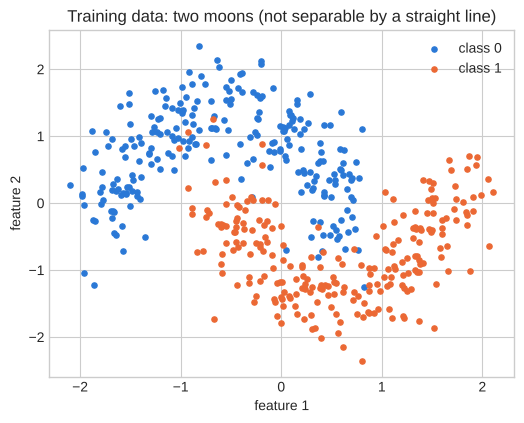

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

# Fixed colour order for every chart in this challenge (series 1, 2, 3, ...)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]

# 1) Create the data: 600 points, 2 features each, label 0 or 1
X_moons, y_moons = make_moons(n_samples=600, noise=0.2, random_state=42)

# 2) Split into training (80%) and test (20%) sets
X_tr, X_te, y_tr, y_te = train_test_split(X_moons, y_moons, test_size=0.2, random_state=42)

# 3) Standardise: mean 0, std 1 (using the TRAINING statistics only, so no test info leaks in)
mean, std = X_tr.mean(axis=0), X_tr.std(axis=0)
X_tr = (X_tr - mean) / std
X_te = (X_te - mean) / std

# 4) Transpose to our "one column per example" convention
X_train_np = X_tr.T                  # shape (2, 480)
X_test_np  = X_te.T                  # shape (2, 120)
Y_train_np = y_tr.reshape(1, -1)     # shape (1, 480)
Y_test_np  = y_te.reshape(1, -1)     # shape (1, 120)
print("X_train:", X_train_np.shape, " Y_train:", Y_train_np.shape)
print("X_test: ", X_test_np.shape,  " Y_test: ", Y_test_np.shape)

plt.figure(figsize=(6, 4.5))
for label, color in zip([0, 1], COLORS):
    pts = X_tr[y_tr == label]
    plt.scatter(pts[:, 0], pts[:, 1], s=14, color=color, label=f"class {label}")
plt.title("Training data: two moons (not separable by a straight line)")
plt.xlabel("feature 1"); plt.ylabel("feature 2"); plt.legend()
plt.show()


## Part 1 — Forward propagation

### Step 1: Activation functions and their derivatives

For backprop we need each activation function **and its derivative** (its slope), because the chain rule multiplies by the slope at every layer.

| Activation | $g(z)$ | Derivative $g'(z)$ | Notes |
|---|---|---|---|
| ReLU | $\max(0, z)$ | 1 if $z>0$, else 0 | slope is 1 for positive inputs, so gradients pass through unchanged |
| Sigmoid | $\frac{1}{1+e^{-z}}$ | $\sigma(z)(1-\sigma(z))$ | slope is **at most 0.25**, so gradients shrink at every layer |
| Tanh | $\tanh(z)$ | $1-\tanh^2(z)$ | slope at most 1, and zero-centred |
| Softmax (output only) | $\frac{e^{z_i}}{\sum_j e^{z_j}}$ | (handled together with the loss) | turns 10 scores into 10 probabilities that sum to 1 |

Keep the **"sigmoid's slope ≤ 0.25"** fact in mind. It explains the *vanishing gradient* problem we'll see in Part 3.


In [11]:
# ----- Activation functions and their derivatives -----
def sigmoid(Z):
    Z = np.clip(Z, -500, 500)          # avoid overflow warnings in np.exp for huge values
    return 1 / (1 + np.exp(-Z))

def sigmoid_derivative(Z):
    s = sigmoid(Z)
    return s * (1 - s)                 # maximum value is 0.25 (at Z = 0)

def relu(Z):
    return np.maximum(0, Z)

def relu_derivative(Z):
    return (Z > 0).astype(float)       # 1 where Z > 0, else 0

def tanh(Z):
    return np.tanh(Z)

def tanh_derivative(Z):
    return 1 - np.tanh(Z) ** 2

def softmax(Z):
    # Subtracting the max doesn't change the result but prevents overflow in np.exp
    expZ = np.exp(Z - Z.max(axis=0, keepdims=True))
    return expZ / expZ.sum(axis=0, keepdims=True)

# Look-up table: name -> (function, derivative)
ACTIVATIONS = {
    "relu":    (relu, relu_derivative),
    "sigmoid": (sigmoid, sigmoid_derivative),
    "tanh":    (tanh, tanh_derivative),
}

# Quick sanity check
z = np.array([-2.0, 0.0, 2.0])
print("relu   ", relu(z),    " slope", relu_derivative(z))
print("sigmoid", sigmoid(z).round(3), " slope", sigmoid_derivative(z).round(3))
print("tanh   ", tanh(z).round(3),    " slope", tanh_derivative(z).round(3))


relu    [0. 0. 2.]  slope [0. 0. 1.]
sigmoid [0.119 0.5   0.881]  slope [0.105 0.25  0.105]
tanh    [-0.964  0.     0.964]  slope [0.071 1.    0.071]


### Step 2: The network class

The whole network lives in one class, `NumpyMLP`. Each method is one step of the learning loop.

**`__init__`: create the weights**
- Weights start as **small random numbers**. Why not all zeros? If every weight were the same, every neuron in a layer would compute the same thing and receive the same update, so they would *stay* identical forever. Randomness "breaks the symmetry".
- *How* small matters (we test this in Part 3). We use well-known rules that keep the signal at a healthy size through the layers:
  - **He initialisation** for ReLU: random normal × $\sqrt{2/n_{in}}$
  - **Xavier initialisation** for sigmoid/tanh: random normal × $\sqrt{1/n_{in}}$
- Biases start at 0 (that's fine, because the random weights already break the symmetry).

**`forward`: forward propagation**, layer by layer:
$$Z^{[l]} = W^{[l]}A^{[l-1]} + b^{[l]}, \qquad A^{[l]} = g(Z^{[l]})$$
The hidden layers use the chosen activation (ReLU/sigmoid/tanh). The output layer uses **sigmoid** (1 output → probability of class 1) or **softmax** (several outputs → one probability per class). We **save** every $Z$ and $A$ in a `cache`, because backprop needs them.

**`compute_loss`: cross-entropy**
- Binary: $\;L = -\frac{1}{m}\sum \big[y\log(\hat y) + (1-y)\log(1-\hat y)\big]$
- Multi-class: $\;L = -\frac{1}{m}\sum \sum_k y_k \log(\hat y_k)$

**`backward`: backpropagation (the chain rule, from the last layer back to the first)**

1. **Output layer.** Using sigmoid + binary cross-entropy (or softmax + cross-entropy), the calculus simplifies to:
$$dZ^{[L]} = A^{[L]} - Y \qquad \text{("prediction minus truth")}$$
2. **For each layer $l$, from $L$ down to 1:**
$$dW^{[l]} = \frac{1}{m}\, dZ^{[l]} \, A^{[l-1]\,T} \qquad db^{[l]} = \frac{1}{m}\sum_{\text{examples}} dZ^{[l]}$$
3. **Pass the error back to the previous layer:**
$$dA^{[l-1]} = W^{[l]\,T} dZ^{[l]}, \qquad dZ^{[l-1]} = dA^{[l-1]} \odot g'(Z^{[l-1]})$$
   ($\odot$ means element-wise multiplication.)

In words: each layer's error is the next layer's error, **sent backwards through the same weights**, then **multiplied by the activation's slope**. That multiplication by the slope at every layer is why the choice of activation matters so much for deep networks.

**`update`: gradient descent**
$$W^{[l]} := W^{[l]} - \alpha\, dW^{[l]}, \qquad b^{[l]} := b^{[l]} - \alpha\, db^{[l]}$$
where $\alpha$ is the **learning rate** (step size).

**`fit`: the training loop.** It repeats forward → loss → backward → update. It can use the full dataset per step (`batch_size=None`) or mini-batches (we need those for MNIST in the Extension). It records the loss and the average gradient size of each layer, so we can visualise them.


In [12]:
class NumpyMLP:
    '''A fully-connected neural network written with NumPy only.

    layer_sizes: e.g. [2, 16, 8, 1] -> 2 inputs, hidden layers of 16 and 8 neurons, 1 output
    hidden_activation: "relu", "sigmoid" or "tanh" (used by all hidden layers)
    init: "auto" (He for ReLU, Xavier otherwise) or a number used as the std of the random weights
    '''

    def __init__(self, layer_sizes, hidden_activation="relu", init="auto", seed=42):
        self.layer_sizes = layer_sizes
        self.L = len(layer_sizes) - 1                       # number of layers with weights
        self.g, self.g_prime = ACTIVATIONS[hidden_activation]
        self.multiclass = layer_sizes[-1] > 1               # >1 output neuron -> softmax
        rng = np.random.default_rng(seed)                   # seed -> reproducible results

        self.params = {}
        for l in range(1, self.L + 1):
            n_in, n_out = layer_sizes[l - 1], layer_sizes[l]
            if init == "auto":
                scale = np.sqrt(2 / n_in) if hidden_activation == "relu" else np.sqrt(1 / n_in)
            else:
                scale = init
            self.params[f"W{l}"] = rng.standard_normal((n_out, n_in)) * scale
            self.params[f"b{l}"] = np.zeros((n_out, 1))

    # ---------------- PART 1: FORWARD PROPAGATION ----------------
    def forward(self, X):
        self.cache = {"A0": X}
        A = X
        for l in range(1, self.L + 1):
            Z = self.params[f"W{l}"] @ A + self.params[f"b{l}"]   # linear step
            if l < self.L:
                A = self.g(Z)                                     # hidden layer activation
            elif self.multiclass:
                A = softmax(Z)                                    # output: class probabilities
            else:
                A = sigmoid(Z)                                    # output: probability of class 1
            self.cache[f"Z{l}"] = Z
            self.cache[f"A{l}"] = A
        return A

    def compute_loss(self, A_out, Y):
        m = Y.shape[1]
        A_out = np.clip(A_out, 1e-12, 1 - 1e-12)                  # avoid log(0)
        if self.multiclass:
            return -np.sum(Y * np.log(A_out)) / m
        return -np.sum(Y * np.log(A_out) + (1 - Y) * np.log(1 - A_out)) / m

    # ---------------- PART 2: BACKPROPAGATION ----------------
    def backward(self, Y):
        m = Y.shape[1]
        grads = {}
        dZ = self.cache[f"A{self.L}"] - Y                         # output layer: prediction - truth
        for l in range(self.L, 0, -1):                            # go backwards: L, L-1, ..., 1
            grads[f"dW{l}"] = (dZ @ self.cache[f"A{l-1}"].T) / m
            grads[f"db{l}"] = np.sum(dZ, axis=1, keepdims=True) / m
            if l > 1:
                dA_prev = self.params[f"W{l}"].T @ dZ             # send error back through the weights
                dZ = dA_prev * self.g_prime(self.cache[f"Z{l-1}"])  # ...times the activation's slope
        self.grads = grads
        return grads

    def update(self, lr):
        for l in range(1, self.L + 1):
            self.params[f"W{l}"] -= lr * self.grads[f"dW{l}"]
            self.params[f"b{l}"] -= lr * self.grads[f"db{l}"]

    # ---------------- TRAINING LOOP ----------------
    def fit(self, X, Y, epochs=1000, lr=0.1, batch_size=None, print_every=None, seed=0):
        rng = np.random.default_rng(seed)
        m = X.shape[1]
        history = {"loss": [], "grad_size": []}
        for epoch in range(1, epochs + 1):
            if batch_size is None:                                # full-batch gradient descent
                batches = [(X, Y)]
            else:                                                 # mini-batch: shuffle, then slice
                idx = rng.permutation(m)
                batches = [(X[:, idx[i:i + batch_size]], Y[:, idx[i:i + batch_size]])
                           for i in range(0, m, batch_size)]
            epoch_loss = 0.0
            for Xb, Yb in batches:
                A_out = self.forward(Xb)                          # 1. forward
                epoch_loss += self.compute_loss(A_out, Yb) * Xb.shape[1]  # 2. loss
                self.backward(Yb)                                 # 3. backward
                self.update(lr)                                   # 4. update
            history["loss"].append(epoch_loss / m)
            # average |gradient| of each layer's weights (used to visualise the backward flow)
            history["grad_size"].append([np.mean(np.abs(self.grads[f"dW{l}"])) for l in range(1, self.L + 1)])
            if print_every and epoch % print_every == 0:
                print(f"Epoch {epoch:5d} | loss = {history['loss'][-1]:.4f}")
        return history

    def predict(self, X):
        A_out = self.forward(X)
        if self.multiclass:
            return np.argmax(A_out, axis=0)
        return (A_out > 0.5).astype(int)

    def accuracy(self, X, Y):
        return float(np.mean(self.predict(X) == Y))


### Step 3: Run the forward pass on an *untrained* network

We build the 3-layer network the challenge asks for: **2 hidden layers + 1 output layer** → `[2, 16, 8, 1]`, with ReLU hidden layers.

Before training, the weights are random, so the network is just guessing. We expect predictions near **0.5** and a loss near $\ln 2 \approx 0.693$ (the cross-entropy you get from guessing 50/50).


In [13]:
net = NumpyMLP([2, 16, 8, 1], hidden_activation="relu")

# Print the shape of every weight matrix and bias vector
for l in range(1, net.L + 1):
    print(f"Layer {l}: W{l} {net.params[f'W{l}'].shape}, b{l} {net.params[f'b{l}'].shape}")

predictions = net.forward(X_train_np)
print("\nShapes flowing forward:")
for l in range(net.L + 1):
    print(f"  A{l}: {net.cache[f'A{l}'].shape}")
print("\nFirst 5 predictions (untrained):", predictions[0, :5].round(3))
print(f"Initial loss: {net.compute_loss(predictions, Y_train_np):.4f}   (ln 2 = {np.log(2):.4f})")
print(f"Initial test accuracy: {net.accuracy(X_test_np, Y_test_np):.3f}")


Layer 1: W1 (16, 2), b1 (16, 1)
Layer 2: W2 (8, 16), b2 (8, 1)
Layer 3: W3 (1, 8), b3 (1, 1)

Shapes flowing forward:
  A0: (2, 480)
  A1: (16, 480)
  A2: (8, 480)
  A3: (1, 480)

First 5 predictions (untrained): [0.432 0.45  0.434 0.412 0.488]
Initial loss: 0.6728   (ln 2 = 0.6931)
Initial test accuracy: 0.542


### Step 4: How do we know our backprop is correct? A gradient check

Backprop code is easy to get subtly wrong. We can check it the slow way: nudge **one** weight by a tiny amount $\epsilon$ and see how much the loss changes:
$$\text{numerical gradient} \approx \frac{L(w+\epsilon) - L(w-\epsilon)}{2\epsilon}$$
If backprop is right, the two numbers should match to many decimal places.


In [14]:
def gradient_check(net, X, Y, eps=1e-5, checks=5, seed=0):
    rng = np.random.default_rng(seed)
    net.forward(X)
    grads = net.backward(Y)                                   # backprop gradients
    max_rel_error = 0.0
    for _ in range(checks):
        l = rng.integers(1, net.L + 1)                        # pick a random layer...
        W = net.params[f"W{l}"]
        i, j = rng.integers(W.shape[0]), rng.integers(W.shape[1])   # ...and a random weight
        original = W[i, j]
        W[i, j] = original + eps; loss_plus  = net.compute_loss(net.forward(X), Y)
        W[i, j] = original - eps; loss_minus = net.compute_loss(net.forward(X), Y)
        W[i, j] = original                                    # put it back
        numerical = (loss_plus - loss_minus) / (2 * eps)
        backprop = grads[f"dW{l}"][i, j]
        rel_error = abs(numerical - backprop) / max(1e-12, abs(numerical) + abs(backprop))
        max_rel_error = max(max_rel_error, rel_error)
        print(f"W{l}[{i},{j}]  backprop = {backprop:+.8f}   numerical = {numerical:+.8f}")
    print(f"\nLargest relative error: {max_rel_error:.2e}  ->",
          "backprop looks correct ✅" if max_rel_error < 1e-5 else "something is wrong ❌")

# tanh is smooth everywhere, which makes the numerical check most reliable
gradient_check(NumpyMLP([2, 5, 4, 1], "tanh", seed=1), X_train_np[:, :50], Y_train_np[:, :50])


W3[0,2]  backprop = +0.09682849   numerical = +0.09682849
W2[1,1]  backprop = +0.13803587   numerical = +0.13803587
W1[0,0]  backprop = +0.23715956   numerical = +0.23715956
W1[4,1]  backprop = +0.04706873   numerical = +0.04706873
W3[0,2]  backprop = +0.09682849   numerical = +0.09682849

Largest relative error: 5.60e-11  -> backprop looks correct ✅


## Part 2 — Training with backpropagation + loss visualisation

Now we run the full loop for 2,000 iterations ("epochs"; here each one uses all 480 training points) with learning rate $\alpha = 0.1$.


Epoch   250 | loss = 0.2373
Epoch   500 | loss = 0.1751
Epoch   750 | loss = 0.1310
Epoch  1000 | loss = 0.1121
Epoch  1250 | loss = 0.1029
Epoch  1500 | loss = 0.0981
Epoch  1750 | loss = 0.0951
Epoch  2000 | loss = 0.0933

Train accuracy: 0.971
Test accuracy:  0.950


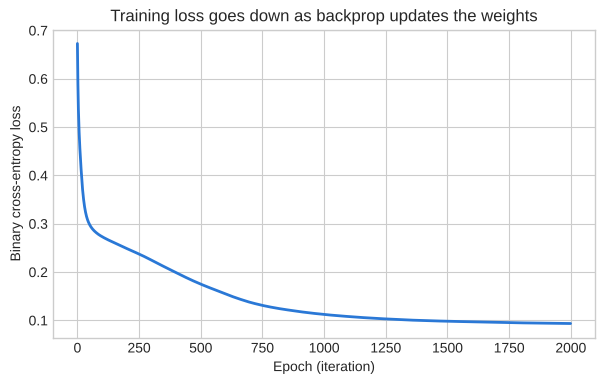

In [15]:
net = NumpyMLP([2, 16, 8, 1], hidden_activation="relu")
history = net.fit(X_train_np, Y_train_np, epochs=2000, lr=0.1, print_every=250)

print(f"\nTrain accuracy: {net.accuracy(X_train_np, Y_train_np):.3f}")
print(f"Test accuracy:  {net.accuracy(X_test_np, Y_test_np):.3f}")

plt.figure(figsize=(7, 4))
plt.plot(history["loss"], color=COLORS[0], linewidth=2)
plt.title("Training loss goes down as backprop updates the weights")
plt.xlabel("Epoch (iteration)"); plt.ylabel("Binary cross-entropy loss")
plt.show()


**Reading the curve:** the loss starts at ≈0.69 (guessing) and falls quickly at first, while the network learns the rough shape. Then it flattens as it fine-tunes the curved boundary.

Let's look at **what** the network learned. The plot below colours every point of the plane by the network's prediction: the **decision boundary**.


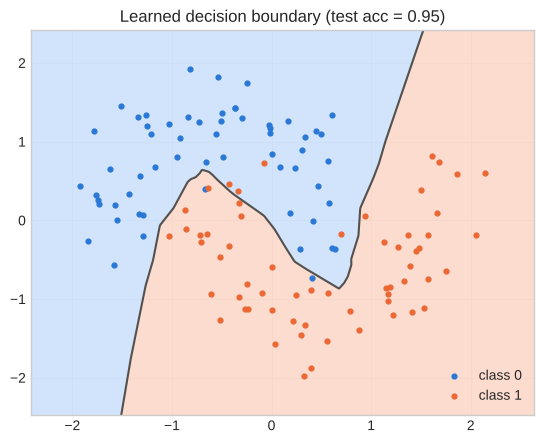

In [16]:
def plot_decision_boundary(net, X_rows, y, title, ax=None):
    # X_rows: data with one ROW per example (scikit-learn style), used for plotting
    ax = ax or plt.gca()
    x_min, x_max = X_rows[:, 0].min() - 0.5, X_rows[:, 0].max() + 0.5
    y_min, y_max = X_rows[:, 1].min() - 0.5, X_rows[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    grid = np.c_[xx.ravel(), yy.ravel()].T                 # shape (2, 90000)
    probs = net.forward(grid).reshape(xx.shape)
    ax.contourf(xx, yy, probs, levels=[0, 0.5, 1], colors=["#cde2fb", "#fbd9c9"], alpha=0.9)
    ax.contour(xx, yy, probs, levels=[0.5], colors="#52514e", linewidths=1.5)
    for label, color in zip([0, 1], COLORS):
        pts = X_rows[y == label]
        ax.scatter(pts[:, 0], pts[:, 1], s=12, color=color, label=f"class {label}")
    ax.set_title(title); ax.legend(loc="lower right")

plt.figure(figsize=(6.5, 5))
plot_decision_boundary(net, X_te, y_te, f"Learned decision boundary (test acc = {net.accuracy(X_test_np, Y_test_np):.2f})")
plt.show()


The boundary is **curved**. A single perceptron could only draw a straight line. The hidden layers with ReLU let the network bend the boundary around the moons.

## Part 3 — Experiments

We change **one thing at a time** and keep everything else fixed (same data, same seed, 2,000 epochs). This is the same "fair test" idea as in Challenge 1.

### Experiment A: activation functions (ReLU vs sigmoid vs tanh)


Setting                       Final loss  Test acc
ReLU                              0.0933     0.950
Sigmoid                           0.2921     0.850
Tanh                              0.1017     0.967


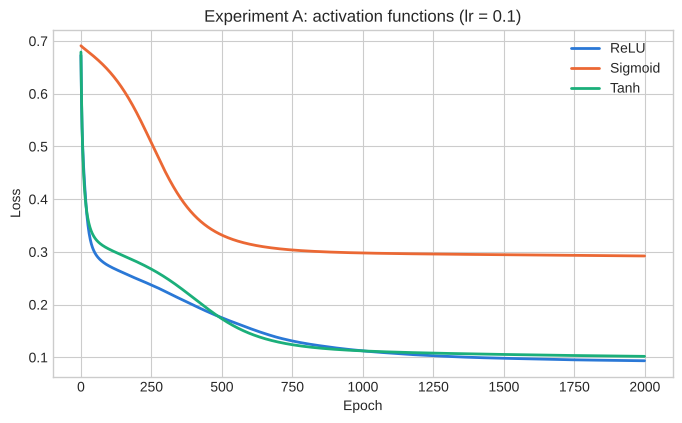

In [17]:
def run_experiment(configs, title, epochs=2000):
    # configs: list of (label, layer_sizes, activation, lr, init)
    plt.figure(figsize=(8, 4.5))
    print(f"{'Setting':<28}{'Final loss':>12}{'Test acc':>10}")
    for (label, sizes, act, lr, init), color in zip(configs, COLORS):
        net_exp = NumpyMLP(sizes, act, init=init)
        with np.errstate(over="ignore", invalid="ignore"):    # silence warnings if training blows up
            h = net_exp.fit(X_train_np, Y_train_np, epochs=epochs, lr=lr)
            acc = net_exp.accuracy(X_test_np, Y_test_np)
        print(f"{label:<28}{h['loss'][-1]:>12.4f}{acc:>10.3f}")
        plt.plot(h["loss"], color=color, linewidth=2, label=label)
    plt.title(title); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()
    plt.show()

run_experiment([
    ("ReLU",    [2, 16, 8, 1], "relu",    0.1, "auto"),
    ("Sigmoid", [2, 16, 8, 1], "sigmoid", 0.1, "auto"),
    ("Tanh",    [2, 16, 8, 1], "tanh",    0.1, "auto"),
], "Experiment A: activation functions (lr = 0.1)")


**Observation:** ReLU and tanh learn quickly and reach low loss. **Sigmoid is clearly the slowest**: after the same 2,000 steps its loss is much higher and its accuracy lower. Sigmoid's slope is at most 0.25, so every layer it passes through **shrinks** the gradient, and the early layers learn slowly.

### Experiment B: learning rates


Setting                       Final loss  Test acc
lr = 0.001                        0.3753     0.850
lr = 0.01                         0.2483     0.867
lr = 0.1                          0.0933     0.950
lr = 1.0                          0.0789     0.958
lr = 5.0                          0.6931     0.492


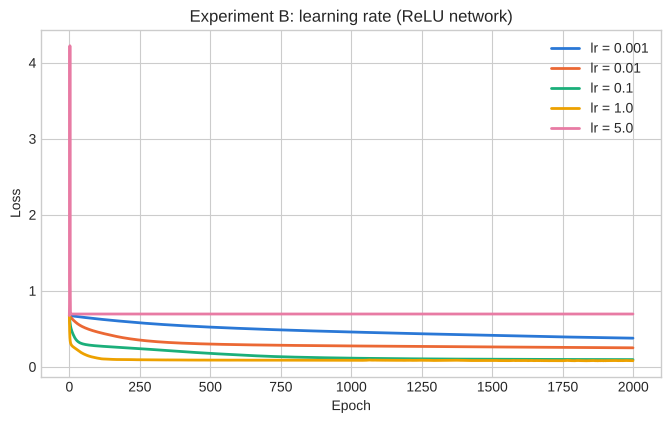

In [18]:
run_experiment([
    ("lr = 0.001", [2, 16, 8, 1], "relu", 0.001, "auto"),
    ("lr = 0.01",  [2, 16, 8, 1], "relu", 0.01,  "auto"),
    ("lr = 0.1",   [2, 16, 8, 1], "relu", 0.1,   "auto"),
    ("lr = 1.0",   [2, 16, 8, 1], "relu", 1.0,   "auto"),
    ("lr = 5.0",   [2, 16, 8, 1], "relu", 5.0,   "auto"),
], "Experiment B: learning rate (ReLU network)")


**Observation:**
- **Too small (0.001)**: the loss barely moves. It's learning, but taking tiny steps, so it would need far more epochs.
- **Good range (0.1 – 1.0)**: fast, smooth progress to a low loss.
- **Too large (5.0)**: the first steps overshoot so badly that the ReLU neurons get pushed into the "always 0" zone (**dead ReLUs**). The gradient becomes 0, learning stops, and the loss stays stuck at ≈0.693, which is just guessing. This is the "overshooting" warning from the earlier notebook made visible.

### Experiment C: network depth (adding a 3rd hidden layer)


Setting                       Final loss  Test acc
2 hidden layers [16, 8]           0.0933     0.950
3 hidden layers [16, 8, 8]        0.0877     0.958


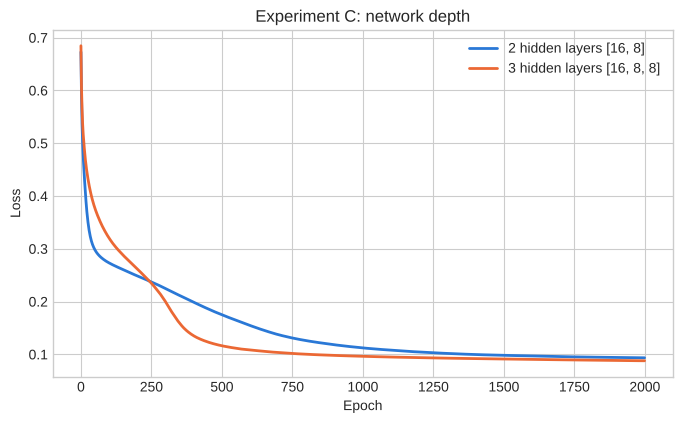

In [19]:
run_experiment([
    ("2 hidden layers [16, 8]",    [2, 16, 8, 1],    "relu", 0.1, "auto"),
    ("3 hidden layers [16, 8, 8]", [2, 16, 8, 8, 1], "relu", 0.1, "auto"),
], "Experiment C: network depth")


**Observation:** the extra layer gives a small improvement. Two hidden layers are already enough for a 2D problem this simple, so going deeper adds computation without much benefit. Depth helps on harder problems (images, speech), **provided the gradients can still flow** through all the layers. That is exactly what we check next.

### Visualising the forward flow of activations

What do the values look like as they travel **forward** through the trained `[2, 16, 8, 1]` ReLU network from Part 2? Each histogram shows all the activation values $A^{[l]}$ produced by a layer for the training set.


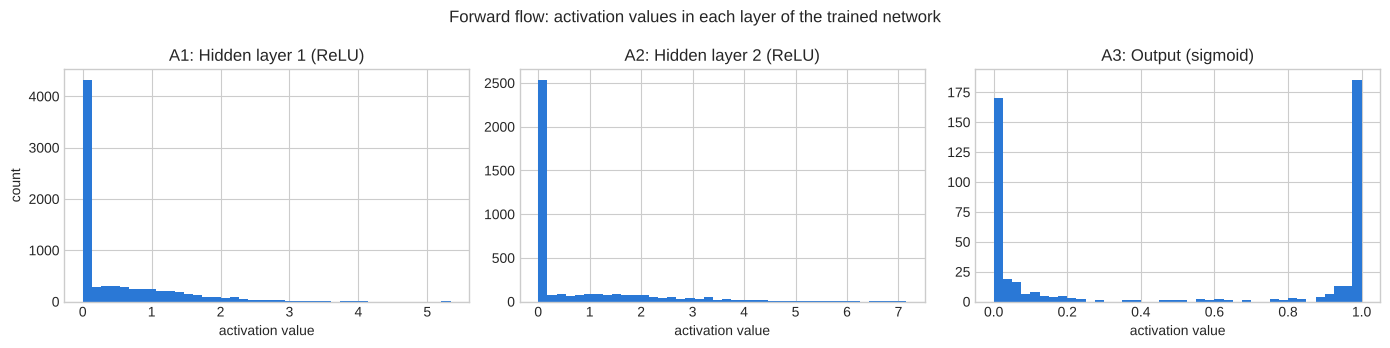

In [20]:
net.forward(X_train_np)    # `net` is the trained network from Part 2
fig, axes = plt.subplots(1, net.L, figsize=(14, 3.5))
names = ["Hidden layer 1 (ReLU)", "Hidden layer 2 (ReLU)", "Output (sigmoid)"]
for l, ax in enumerate(axes, start=1):
    ax.hist(net.cache[f"A{l}"].ravel(), bins=40, color=COLORS[0])
    ax.set_title(f"A{l}: {names[l-1]}"); ax.set_xlabel("activation value")
axes[0].set_ylabel("count")
plt.suptitle("Forward flow: activation values in each layer of the trained network")
plt.tight_layout(); plt.show()


- Hidden layers: a tall bar at **0** (ReLU switches off neurons whose $Z$ is negative) plus a spread of positive values. Each neuron "fires" only for some regions of the input.
- Output: values are pushed towards **0 or 1**. The trained network is **confident** about most points, which is why the loss is low.

### Visualising the backward flow of gradients

During training we recorded the average size of each layer's weight gradient $|dW^{[l]}|$ (`history["grad_size"]`). This is how strongly the error signal arrives at each layer.


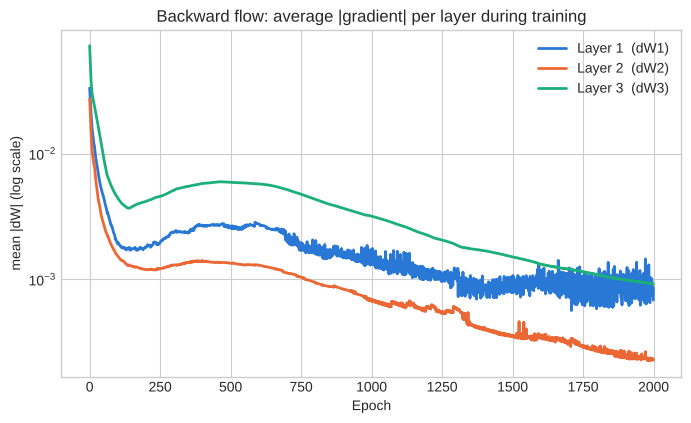

In [21]:
grad_size = np.array(history["grad_size"])        # shape (epochs, layers)
plt.figure(figsize=(8, 4.5))
for l, color in zip(range(net.L), COLORS):
    plt.plot(grad_size[:, l], color=color, linewidth=2, label=f"Layer {l+1}  (dW{l+1})")
plt.yscale("log")
plt.title("Backward flow: average |gradient| per layer during training")
plt.xlabel("Epoch"); plt.ylabel("mean |dW| (log scale)"); plt.legend()
plt.show()


Gradients are largest at the start, when the network is very wrong. They shrink as the loss falls, because there is less error left to correct. In this **shallow ReLU** network, all layers receive gradients of a similar size, so the gradient flows well. Now let's see what happens in a **deep** network.

### Vanishing gradients: a deep network (8 hidden layers), sigmoid vs ReLU

We build `[2, 16, 16, 16, 16, 16, 16, 16, 16, 1]`, run **one** forward + backward pass, and measure the gradient size at each layer.


sigmoid: first-layer gradient = 2.1e-07, last-layer gradient = 3.3e-02  (ratio 158,309x)
   relu: first-layer gradient = 3.4e-03, last-layer gradient = 1.1e-02  (ratio 3x)


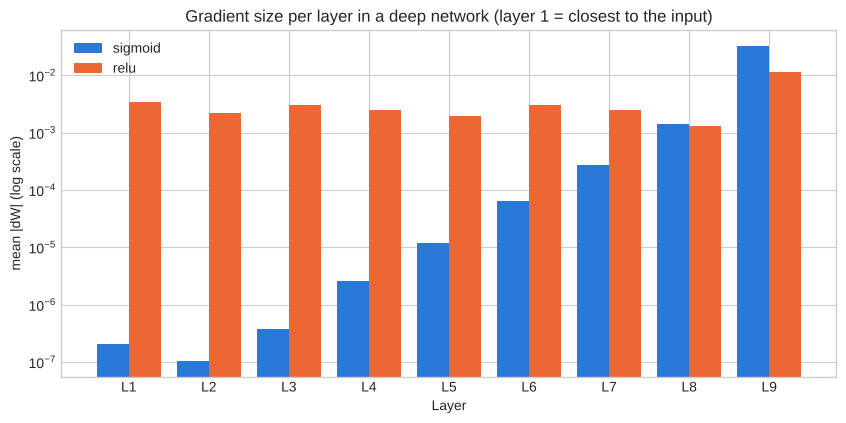


Now train both deep networks for 2,000 epochs:
  deep sigmoid: final loss = 0.6931, test acc = 0.492
  deep    relu: final loss = 0.0585, test acc = 0.942


In [22]:
deep_sizes = [2] + [16] * 8 + [1]
layers = np.arange(1, len(deep_sizes))
bar_w = 0.4
plt.figure(figsize=(10, 4.5))
for k, (act, color) in enumerate(zip(["sigmoid", "relu"], COLORS)):
    deep = NumpyMLP(deep_sizes, act)
    deep.forward(X_train_np)
    g = deep.backward(Y_train_np)
    sizes = [np.mean(np.abs(g[f"dW{l}"])) for l in layers]
    print(f"{act:>7}: first-layer gradient = {sizes[0]:.1e}, last-layer gradient = {sizes[-1]:.1e}"
          f"  (ratio {sizes[-1] / sizes[0]:,.0f}x)")
    plt.bar(layers + (k - 0.5) * bar_w, sizes, width=bar_w, color=color, label=act)
plt.yscale("log")
plt.xticks(layers, [f"L{l}" for l in layers])
plt.title("Gradient size per layer in a deep network (layer 1 = closest to the input)")
plt.xlabel("Layer"); plt.ylabel("mean |dW| (log scale)"); plt.legend()
plt.show()

print("\nNow train both deep networks for 2,000 epochs:")
for act in ["sigmoid", "relu"]:
    deep = NumpyMLP(deep_sizes, act)
    h = deep.fit(X_train_np, Y_train_np, epochs=2000, lr=0.1)
    print(f"  deep {act:>7}: final loss = {h['loss'][-1]:.4f}, test acc = {deep.accuracy(X_test_np, Y_test_np):.3f}")


**This is the vanishing gradient problem, made visible.**
- With **sigmoid**, the gradient reaching layer 1 is more than **100,000× smaller** than at the last layer. Every layer multiplies the error by a slope ≤ 0.25: $0.25^8 \approx 0.000015$. The early layers receive almost no signal, so they barely learn. The deep sigmoid network gets **stuck at loss ≈ 0.693 (≈50% accuracy)**. It learned nothing in 2,000 epochs.
- With **ReLU**, the slope is exactly 1 for active neurons, so the gradient reaches every layer at a similar size. The deep ReLU network trains fine.

This is the main reason ReLU replaced sigmoid in hidden layers.

### Exploding / vanishing signals: the role of weight initialisation

The *size* of the starting weights matters too. Using the same 8-hidden-layer ReLU network, we compare three initialisations and measure how big the activations are at each layer (their standard deviation):
- `0.01`: tiny weights
- `"auto"`: He initialisation, std = $\sqrt{2/n_{in}}$ ≈ 0.35 here
- `1.0`: large weights


init tiny (0.01) : activation std in layer 8 = 1.3e-14, final loss = 0.6931, test acc = 0.492
init He (auto)   : activation std in layer 8 = 8.7e-02, final loss = 0.0585, test acc = 0.942
init large (1.0) : activation std in layer 8 = 1.3e+02, final loss = nan, test acc = 0.492


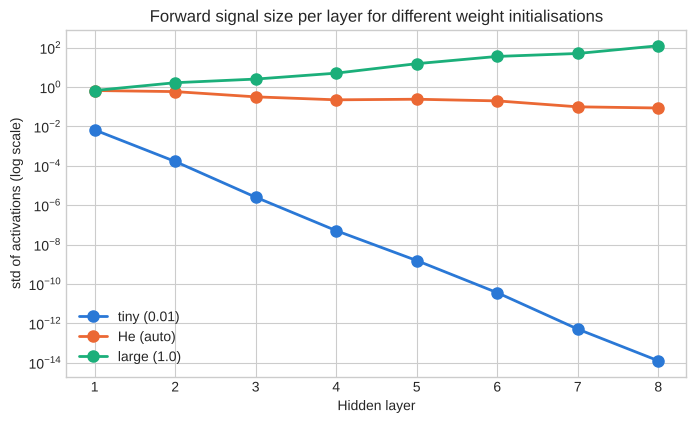

In [23]:
plt.figure(figsize=(8, 4.5))
for (label, init), color in zip([("tiny (0.01)", 0.01), ("He (auto)", "auto"), ("large (1.0)", 1.0)], COLORS):
    deep = NumpyMLP(deep_sizes, "relu", init=init)
    deep.forward(X_train_np)
    stds = [np.std(deep.cache[f"A{l}"]) for l in range(1, deep.L)]   # hidden layers only
    plt.plot(range(1, deep.L), stds, marker="o", markersize=8, linewidth=2, color=color, label=label)
    with np.errstate(over="ignore", invalid="ignore"):
        h = deep.fit(X_train_np, Y_train_np, epochs=2000, lr=0.1)
        acc = deep.accuracy(X_test_np, Y_test_np)
    print(f"init {label:<12}: activation std in layer 8 = {stds[-1]:.1e}, "
          f"final loss = {h['loss'][-1]:.4f}, test acc = {acc:.3f}")
plt.yscale("log")
plt.title("Forward signal size per layer for different weight initialisations")
plt.xlabel("Hidden layer"); plt.ylabel("std of activations (log scale)"); plt.legend()
plt.show()


**Observation:**
- **Tiny weights (0.01):** the signal shrinks ~40× at every layer and is almost **zero** by layer 8 (≈1e-14). The output barely depends on the input, the gradients vanish, and the network stays at 50% accuracy.
- **Large weights (1.0):** the signal **explodes** (×2–3 per layer). Values become huge, the first update overshoots, the numbers overflow, and the loss becomes `nan` (*not a number*). This is the **exploding gradient** problem.
- **He initialisation** keeps the signal at roughly the same size through all the layers, so the network trains well.

### 🎨 Bonus: diagram of how data and gradients flow


/tmp/claude-0/-home-user/6267b732-921a-5607-97e9-7e3ab0b129b9/scratchpad/venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8857 (\N{CIRCLED DOT OPERATOR}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


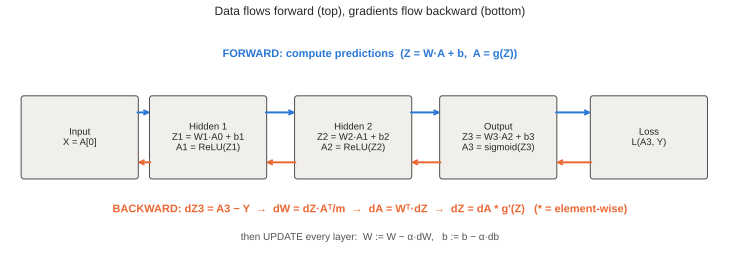

In [24]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(13, 4.2))
ax.set_xlim(0, 13); ax.set_ylim(0, 4.2); ax.axis("off")
boxes = [("Input\nX = A[0]", 0.3), ("Hidden 1\nZ1 = W1·A0 + b1\nA1 = ReLU(Z1)", 2.6),
         ("Hidden 2\nZ2 = W2·A1 + b2\nA2 = ReLU(Z2)", 5.2), ("Output\nZ3 = W3·A2 + b3\nA3 = sigmoid(Z3)", 7.8),
         ("Loss\nL(A3, Y)", 10.5)]
for text, x in boxes:
    ax.add_patch(FancyBboxPatch((x, 1.4), 2.0, 1.4, boxstyle="round,pad=0.05", fc="#f0efec", ec="#52514e"))
    ax.text(x + 1.0, 2.1, text, ha="center", va="center", fontsize=9.5)
for (_, x1), (_, x2) in zip(boxes[:-1], boxes[1:]):
    ax.annotate("", xy=(x2, 2.55), xytext=(x1 + 2.0, 2.55),
                arrowprops=dict(arrowstyle="->", color=COLORS[0], lw=2))          # forward
    ax.annotate("", xy=(x1 + 2.0, 1.65), xytext=(x2, 1.65),
                arrowprops=dict(arrowstyle="->", color=COLORS[1], lw=2))          # backward
ax.text(6.5, 3.55, "FORWARD: compute predictions  (Z = W·A + b,  A = g(Z))", ha="center", color=COLORS[0], fontsize=11, weight="bold")
ax.text(6.5, 0.75, "BACKWARD: dZ3 = A3 − Y  →  dW = dZ·Aᵀ/m  →  dA = Wᵀ·dZ  →  dZ = dA * g'(Z)   (* = element-wise)", ha="center", color=COLORS[1], fontsize=11, weight="bold")
ax.text(6.5, 0.25, "then UPDATE every layer:  W := W − α·dW,   b := b − α·db", ha="center", color="#52514e", fontsize=10)
plt.title("Data flows forward (top), gradients flow backward (bottom)")
plt.show()


## 📝 Reflection (≈190 words)

Building the network by hand showed me that "learning" is just a repeated loop: predict, measure the error, send the error backwards with the chain rule, and nudge every weight downhill. The loss curves made the learning dynamics visible. Loss falls steeply while the network finds the rough shape of the data, then slowly levels off while it refines the curved boundary. The learning rate controlled this strongly: 0.001 barely moved in 2,000 steps, 0.1–1.0 converged smoothly, and 5.0 overshot so hard that the ReLU neurons died and the loss froze at chance level (≈0.693).

Activations and initialisation mattered even more in deeper networks. Because each layer multiplies the backward signal by the activation's slope, sigmoid (slope ≤ 0.25) shrank the gradient more than 100,000× across eight layers. The early layers never learned and the network stayed at 50% accuracy, while ReLU trained easily. Initialisation had a similar effect on the forward signal: tiny weights made activations vanish, large weights made them explode into `nan`, and He initialisation kept them stable. The gradient check gave me confidence that the backprop maths was correct before I trusted any experiment.


---
# ✅ Extension (Optional): Using My NumPy Network as a Classifier

## Part A: XOR

XOR is the classic problem a single perceptron **cannot** solve: no straight line separates `(0,1),(1,0)` from `(0,0),(1,1)`. The PyTorch `SimpleMLP` in the first notebook solved it, so let's check that our from-scratch network can too.


In [25]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float).T   # shape (2, 4): one column per example
Y_xor = np.array([[0, 1, 1, 0]])                                     # shape (1, 4)

xor_net = NumpyMLP([2, 4, 4, 1], hidden_activation="tanh")
h_xor = xor_net.fit(X_xor, Y_xor, epochs=3000, lr=0.5, print_every=1000)

probs = xor_net.forward(X_xor)[0]
for (a, b), p, target in zip(X_xor.T, probs, Y_xor[0]):
    print(f"input ({int(a)}, {int(b)}) -> predicted {p:.4f}   (target {target})")


Epoch  1000 | loss = 0.0012
Epoch  2000 | loss = 0.0005
Epoch  3000 | loss = 0.0003
input (0, 0) -> predicted 0.0002   (target 0)
input (0, 1) -> predicted 0.9997   (target 1)
input (1, 0) -> predicted 0.9997   (target 1)
input (1, 1) -> predicted 0.0006   (target 0)


All four XOR cases are predicted correctly (close to 0 or 1). The hidden layers transform the inputs into a new representation where the classes *can* be separated.

## Part B: MNIST digits, my NumPy network vs. the frameworks

Now the real test: the **same architecture** as the Keras/PyTorch/TF models (`784 → 128 → 64 → 10`), trained on the same 60,000 images, for 5 epochs, with mini-batches of 64. The differences:
- the output layer uses **softmax** with 10 neurons, so labels must be **one-hot encoded** (digit 3 → `[0,0,0,1,0,0,0,0,0,0]`);
- we use plain **SGD** (gradient descent on mini-batches) with lr = 0.1 instead of Adam.


In [26]:
# Re-use the flattened, [0,1]-scaled arrays from the workshop. Transpose to one column per image.
X_mnist_train = x_train_flat.T.astype(np.float64)     # (784, 60000)
X_mnist_test  = x_test_flat.T.astype(np.float64)      # (784, 10000)
Y_mnist_train = np.eye(10)[y_train_tf].T              # one-hot labels: (10, 60000)

mnist_net = NumpyMLP([784, 128, 64, 10], hidden_activation="relu")

start_time = time.time()
h_mnist = mnist_net.fit(X_mnist_train, Y_mnist_train, epochs=5, lr=0.1, batch_size=64, print_every=1)
numpy_training_time = time.time() - start_time

numpy_test_acc = float(np.mean(mnist_net.predict(X_mnist_test) == y_test_tf))
print(f"\nNumPy MLP Training Time: {numpy_training_time:.2f} seconds")
print(f"NumPy MLP Test Accuracy: {numpy_test_acc:.4f}")


Epoch     1 | loss = 0.3289
Epoch     2 | loss = 0.1510
Epoch     3 | loss = 0.1073
Epoch     4 | loss = 0.0850
Epoch     5 | loss = 0.0696

NumPy MLP Training Time: 5.25 seconds
NumPy MLP Test Accuracy: 0.9744


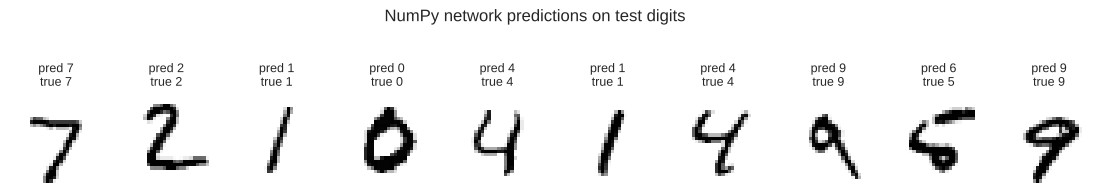


Implementation                Train time (s)   Test accuracy
------------------------------------------------------------
Keras                                  11.73          0.9767
PyTorch                                38.16          0.9638
TensorFlow Core                        13.86          0.9776
PyTorch (pre-loaded data)               7.56          0.9743
NumPy from scratch (SGD)                5.25          0.9744


In [27]:
# Look at a few test images with the NumPy network's predictions
sample_idx = np.arange(10)
preds = mnist_net.predict(X_mnist_test[:, sample_idx])
fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for ax, i, p in zip(axes, sample_idx, preds):
    ax.imshow(x_test_tf[i], cmap="gray_r"); ax.axis("off")
    ax.set_title(f"pred {p}\ntrue {y_test_tf[i]}", fontsize=9)
plt.suptitle("NumPy network predictions on test digits", y=1.15)
plt.show()

# Final comparison: everything trained for 5 epochs with the same 784-128-64-10 architecture
all_results = dict(results)
all_results["PyTorch (pre-loaded data)"] = {"time": pytorch_fast_time, "accuracy": pytorch_fast_acc}
all_results["NumPy from scratch (SGD)"] = {"time": numpy_training_time, "accuracy": numpy_test_acc}
print(f"\n{'Implementation':<28}{'Train time (s)':>16}{'Test accuracy':>16}")
print("-" * 60)
for name, r in all_results.items():
    print(f"{name:<28}{r['time']:>16.2f}{r['accuracy']:>16.4f}")


**What this comparison shows:**
- Our ~100 lines of NumPy reach **about the same accuracy (~97%)** as Keras, PyTorch and TensorFlow. There's no hidden magic in the frameworks: they compute the same forward pass, backprop and weight update we wrote by hand.
- For a small MLP like this, NumPy is not even slow, because the heavy work is matrix multiplication (`@`), which NumPy hands to optimised C/BLAS code.

**So why use a framework?** Because the frameworks give us:
- **automatic differentiation**: no need to derive and debug `backward()` by hand for every new layer type;
- **GPU acceleration** for large models (CNNs, transformers);
- ready-made layers, optimizers (Adam), data loaders, saving/loading and deployment tools.

Writing it from scratch is the best way to *understand* neural networks. Frameworks are the practical way to *build* real ones.



### Workshop Summary

Today we covered the essential theory and practice of Multi-Layered Perceptrons.

* **Core Concepts**: We learned that MLPs are inspired by the brain and are built from layers of artificial neurons.
* **Mechanism**: Each neuron performs a `weighted sum -> activation` calculation.
* **Learning**: The network learns through a two-step process of **Feedforward** (to predict) and **Backpropagation** (to correct errors).
* **Implementation**: We saw that while the code syntax for Keras, PyTorch, and TensorFlow is different, the underlying principles of defining, training, and evaluating a model are the same.

You now have a foundational understanding of one of the most important models in machine learning. Great work!
